# 6. Protocolo y validación estadística

In [1]:
# Preparación: acceso a los resultados versionados y a las funciones que generan las
# tablas y figuras del informe.
import sys
sys.path.insert(0, '../ModeloOriginal')
from src import informe as inf

## 6.1. El protocolo pre-registrado

Antes de ejecutar los experimentos definitivos se congeló
[`ModeloOriginal/experiments/protocolo.md`](https://github.com/RubenEsg/Prediccion-de-fuga-de-clientes-en-fintech/blob/main/ModeloOriginal/experiments/protocolo.md)
con la etiqueta de Git `protocolo-modelo-original-v1`. Fija las hipótesis, las métricas, las particiones, las
repeticiones y semillas, las pruebas con su corrección por comparaciones múltiples, el presupuesto de ajuste y los
conjuntos adicionales. El texto completo está en el [apéndice de código](codigo_modelo_original); la
{ref}`Tabla 6.1 <tab-protocolo>` lo resume y la {ref}`Tabla 6.2 <tab-registro>` comprueba las fechas.

(tab-protocolo)=
**Tabla 6.1.** Resumen del protocolo pre-registrado.

| Elemento | Lo que se fijó |
|---|---|
| Hipótesis confirmatorias | H1: el RMSE del original es menor que el del mejor benchmark. H2: su AUC es mayor |
| Hipótesis secundarias | H3: conjuntos de predicción más cortos que los intervalos del mejor benchmark, con la cobertura nominal. H4: menor pérdida logarítmica que el mejor benchmark recalibrado |
| Métrica principal | AUC en clasificación y RMSE en regresión, las de las entregas anteriores |
| Particiones | Prueba del 20 % (semilla 42); validación anidada {cite}`cawley2010` de 3 × 5 pliegues externos y 3 internos (semillas 42, 43 y 44) |
| Modelos | Diez por tarea: siete de clase, EBM, LightGBM y el original, con el mismo preprocesamiento |
| Presupuesto | El de cada benchmark en el Entregable 3 (30 a 48 evaluaciones por búsqueda); el original, 30 |
| Pruebas | P1 Friedman {cite}`friedman1937` con la corrección de Iman-Davenport {cite}`iman1980` y Wilcoxon {cite}`wilcoxon1945`; P2 *t* corregida de Nadeau-Bengio {cite}`nadeau2003`; P3 DeLong {cite}`delong1988` en clasificación y permutación pareada en regresión; P4 McNemar {cite}`mcnemar1947` en clasificación y bootstrap BCa {cite}`efron1987` en regresión |
| Comparaciones múltiples | Holm {cite}`holm1979` dentro de cada prueba, nueve comparaciones; α = 0,05 |
| Tamaño del efecto | δ de Cliff y *d* de Cohen entre los valores por pliegue; no despreciable si δ llega a 0,147 en valor absoluto {cite}`romano2006` o *d* a 0,2 |
| Veredicto | Las cuatro condiciones de la guía (§6.4), por tarea |

(tab-registro)=
**Tabla 6.2.** Registro del protocolo: fecha de la etiqueta, primera corrida definitiva y cambios posteriores en el
modelo y en el protocolo.

In [2]:
# Tabla 6.2. Consulta a Git la fecha de la etiqueta y si original_model.py o
# protocolo.md cambiaron después de ella, y lee de resultados/progreso.log cuándo
# terminó la primera corrida definitiva.
inf.tabla('tabla_registro')

| Comprobación | Resultado |
| :--- | :--- |
| Etiqueta de Git | `protocolo-modelo-original-v1`, sobre la confirmación `3f6e9ad` |
| Fecha de la etiqueta (la guarda Git dentro de ella) | 2026-11-17 20:12:30 -0500 |
| Primera corrida definitiva | LightGBM, clasificación, semilla 42: terminó a las 20:26 del 2026-11-17 tras 795 s, es decir, empezó entre las 20:12:45 y las 20:13:44 (`resultados/progreso.log`) |
| ¿La etiqueta es anterior a la primera corrida? | Sí |
| `src/original_model.py` desde la etiqueta | Sin cambios |
| `experiments/protocolo.md` desde la etiqueta | Sin cambios |


**Iteraciones de diseño.** La guía pide informar cuántas se evaluaron. Fueron cinco ({ref}`Tabla 6.3 <tab-iteraciones>`),
todas con la partición de entrenamiento (los cinco pliegues externos de la semilla 42) y sin búsqueda de
hiperparámetros; ni la prueba, ni las repeticiones 2 y 3, ni los conjuntos adicionales intervinieron. Esos cinco
pliegues son también cinco de los quince de la comparación confirmatoria: el diseño se eligió mirándolos, de modo que en
ellos la comparación puede favorecer al original. Las cifras de la tabla son las que se anotaron durante el diseño; los
pilotos no dejaron resultados versionados, y por eso es la única tabla del libro que no se regenera desde archivos.

(tab-iteraciones)=
**Tabla 6.3.** Iteraciones de diseño del modelo original, anteriores al registro del protocolo.

| N.º | Idea | Resultado en los pliegues de entrenamiento | Decisión |
|---|---|---|---|
| 1 | Ordenar a los clientes con un regresor del puntaje (XGBoost) en lugar de un clasificador | AUC 0,8289, frente a 0,8314 del clasificador | Descartada: el error del índice cerca del umbral cuesta más de lo que aporta el puntaje |
| 2 | Separar índice y escalón con componentes de XGBoost y escalón duro | AUC 0,812 con escalón duro; 0,831 suavizado | Descartada como estaba: el índice no era lo bastante preciso |
| 3 | BDL: EM generalizado con paso de boosting y salida conforme empírica | RMSE 0,05888 (XGBoost ajustado: 0,05898); AUC 0,8314 (XGBoost: 0,8332) | Se conserva la regla de aprendizaje; la salida de clasificación queda por debajo |
| 4 | Ingeniería: varios árboles por vuelta, calentamiento con parada temprana, mezcla inicial sobre el histograma, regla de parsimonia para $K$ | Mismo error; el ajuste baja de 31 s a 3–8 s y $K = 5$ en todas las configuraciones | Adoptada |
| 5 | Salida de clasificación con la mezcla y dispersión robusta | AUC 0,8345 (techo en entrenamiento: 0,8348) | Adoptada |

## 6.2. Desviaciones del protocolo

Se declaran todas, también las que no cambian ningún resultado.

1. **La etiqueta se publicó unas horas después de crearla.** La etiqueta se creó en el repositorio local a las 20:12 del
   17 de noviembre, antes de lanzar la primera corrida definitiva, y se subió a GitHub a las 00:29 del 18, sin
   resultados. La fecha de la etiqueta la escribe el equipo donde se crea ({ref}`Tabla 6.2 <tab-registro>`): es una
   evidencia, no la certificación de un tercero. La única fecha que certifica un tercero es la de la subida, y para
   entonces ya se habían ejecutado la repetición de la semilla 42 de LightGBM y del modelo original, la evaluación en
   prueba, las pruebas de hipótesis con esa repetición, las diez semillas, la curva de aprendizaje con el estudio de
   columnas y tres de los cuatro conjuntos adicionales (Seguros, Energía y Abulón). Terminaron después de la subida la
   ablación, el cuarto conjunto (California), el cambio de distribución, el ruido y la sensibilidad, y se ejecutaron por
   completo después las repeticiones 2 y 3 de la validación anidada y los análisis del punto 5.
2. **Los guiones de análisis se escribieron después del registro.** El protocolo fija qué se calcula; los guiones `03` a
   `08`, que lo calculan, son posteriores. Al ejecutarlos apareció un fallo en `03_prueba.py` (las predicciones del
   Entregable 3 estaban guardadas en otro orden de filas); el guion se detenía antes de producir nada, y se corrigió
   alineando las filas por su índice. También se añadió un candado a la tabla maestra (`src/registro.py`) para que dos
   colas de experimentos pudieran escribir en ella a la vez; no cambia lo que se calcula.
3. **Lectura más estricta de las condiciones 2 y 3.** El protocolo dice «rechazan la igualdad» y pone el umbral del
   tamaño del efecto en valor absoluto. Al ver que en clasificación el efecto era negativo, se precisó que un rechazo
   solo cuenta si la diferencia favorece al original y que el efecto debe tener ese mismo signo. La precisión solo puede
   endurecer el veredicto, nunca favorecer al modelo propio.
4. **El protocolo no decía cómo romper los empates de la campaña.** La prueba P4 de clasificación marca como positivo
   el 25 % de clientes de mayor puntaje de cada modelo. El guion de las pruebas resuelve los empates del corte por
   posición en la tabla, igual para todos los modelos; esa regla se escribió antes de ejecutar la prueba, pero después
   del registro. El mejor benchmark casi no tiene empates en el corte; el árbol de decisión tiene muchos y el modelo
   original, todavía más, y su captura depende de ellos. La {ref}`Tabla 6.11 <tab-empates>` repite P4 con 2.000
   desempates al azar y dice cuánto depende de ellos su resultado.
5. **Análisis añadidos después de ver los resultados.** Ninguno estaba en el protocolo. Se añadieron para explicar el
   veredicto, como pide la guía cuando no hay superioridad, o para atender un requisito de la guía que el protocolo no
   recogía; son exploratorios y no intervienen en el veredicto:
   - la comparación del predictor óptimo con el mejor benchmark ({ref}`Tabla 6.10 <tab-optimo>`);
   - la sensibilidad a los empates de la campaña ({ref}`Tabla 6.11 <tab-empates>`);
   - la curva de aprendizaje del modelo sin la mezcla ({ref}`Tabla 7.8 <tab-muestra>`);
   - las referencias homogéneas: el MAE del benchmark desplazado a la mediana, su conjunto de predicción por densidad
     ({ref}`Tabla 7.12 <tab-incertidumbre>`) y, en la sensibilidad, el benchmark con sus hiperparámetros finales
     ({ref}`Tabla 7.5 <tab-sensibilidad>`);
   - el error del índice de cada modelo (sección 5.1) y el intervalo de confianza de la diferencia de AUC en prueba
     (sección 6.7);
   - el *Model Confidence Set* de la regresión ({ref}`Tabla 3.3 <tab-benchmarks>`), que la guía pide para la selección
     de combinaciones;
   - los métodos recientes con sus hiperparámetros recomendados ({ref}`Tabla 3.5 <tab-recomendados>`);
   - la memoria de cada modelo y el tiempo de inferencia según el número de filas (sección 7.3 y sección 7.5), que son
     medidas de cómputo;
   - los desgloses descriptivos que acompañan a las tablas: qué pliegues eligieron la mezcla o el puntaje en los
     conjuntos adicionales y la cobertura por número de productos activos.
6. **Lo que no cambió.** El código del modelo y el texto del protocolo son los de la etiqueta
   ({ref}`Tabla 6.2 <tab-registro>`). No se cambiaron hipótesis, métricas, particiones, semillas, pruebas, corrección
   por comparaciones múltiples, presupuesto ni conjuntos adicionales, y no se repitió ninguna corrida para elegir la
   mejor.

## 6.3. Equidad de la comparación

- **Mismas particiones y semilla.** Todos los modelos usan los mismos pliegues externos e internos en cada repetición
  (`src/optimizacion.construir_cv`), el mismo preprocesamiento y las mismas 48 variables.
- **Presupuesto.** Ningún benchmark recibió menos evaluaciones que el original (sección 3.2); el presupuesto y el tiempo
  reales de cada uno están en la {ref}`Tabla 3.3 <tab-benchmarks>`.
- **Benchmarks bien ajustados.** Cada benchmark entra con su mejor combinación de balanceo y optimizador entre las del
  Entregable 3, y hay dos métodos recientes (EBM y LightGBM); la sección 3.6 los compara con sus hiperparámetros
  recomendados.
- **Lo que el original usa y los benchmarks no.** En clasificación, el original recibe el puntaje continuo de las filas
  de entrenamiento además de la etiqueta. No es una ventaja oculta sino el mecanismo que se evalúa: la etiqueta es una
  dicotomización de ese puntaje, y la hipótesis es que desecharlo cuesta precisión. La ablación «sin puntaje» mide cuánto
  aporta (sección 5.9).
- **Varianza por semilla.** Cada modelo final se reajustó con diez semillas (sección 7.3).

## 6.4. El techo del problema

Antes de comparar conviene saber cuánto margen hay. En COFINFAD se puede calcular: como el puntaje es un índice menos
un escalón de 0,05 por producto activo, y esa variable no se puede predecir con las demás, la mejor predicción posible
tiene forma cerrada (Proposición 5 y `experiments/04b_techo.py`). La {ref}`Tabla 6.4 <tab-techo>` compara ese límite
con el mejor benchmark y con el modelo original.

(tab-techo)=
**Tabla 6.4.** Límite teórico de cada métrica en prueba, valor del mejor benchmark y del modelo original, y parte de la
distancia al límite que cierra el original.

In [3]:
# Tabla 6.4. Lee resultados/techo.json (el límite, calculado con la distribución de
# active_products en entrenamiento) y resultados/metricas_prueba.csv (las métricas
# de los diez modelos en prueba).
inf.tabla('tabla_techo')

| Métrica en prueba | Mejor benchmark | Benchmark | Original | Límite teórico | Parte de la distancia al límite que cierra el original |
| :--- | :--- | ---: | ---: | ---: | ---: |
| RMSE | XGBoost | 0,05917 | 0,05912 | 0,05911 | 86 % |
| MAE (el original predice la mediana) | XGBoost | 0,04706 | 0,04510 | 0,04508 | 99 % |
| AUC | XGBoost | 0,8283 | 0,8311 | 0,8313 | 92 % |
| Pérdida logarítmica (benchmark recalibrado) | XGBoost | 0,3675 | 0,3688 | 0,3652 | −55 % |

Límite teórico: el valor que obtiene en la muestra de prueba el predictor óptimo, el que conoce el índice real de cada cliente (δ = 0,050 y los pesos de los cinco niveles estimados en entrenamiento: 0,402, 0,301, 0,149, 0,099, 0,050). En esperanza ningún modelo lo mejora; en una muestra concreta un modelo puede quedar del otro lado por azar (le ocurre a la variante «BDL sin mezcla (K = 1)», con un RMSE de 0,059099 frente a 0,059105). La última columna describe esta muestra (un porcentaje negativo indica que el original queda más lejos del límite que el benchmark): las diferencias en prueba entre el original y el benchmark no son significativas tras el ajuste de Holm (tablas 6.7 y 6.8), así que no mide un aporte demostrado.


Los benchmarks ya están a milésimas del límite. Eso acota de antemano el tamaño de cualquier mejora, y es la razón por
la que el veredicto de este capítulo depende de pruebas pareadas, que son las que pueden detectar diferencias pequeñas
y sistemáticas.

## 6.5. Resultados

Las tablas {ref}`6.5 <tab-resumen-regresion>` y {ref}`6.6 <tab-resumen-clasificacion>` resumen los diez modelos de cada
tarea: media ± desviación de la métrica principal en los pliegues externos, valor en prueba con su intervalo de
confianza bootstrap, y costo de cómputo (tiempo de ajuste y de inferencia y tamaño del modelo, medidos al reajustar
cada modelo final con diez semillas).

(tab-resumen-regresion)=
**Tabla 6.5.** Regresión: RMSE de los diez modelos en los pliegues externos y en prueba, con intervalo de confianza
del 95 % (bootstrap BCa, 2.000 réplicas) y costo de cómputo.

In [4]:
# Tabla 6.5. Une la métrica por pliegue externo (pliegues_regresion.csv), el RMSE en
# prueba con su intervalo BCa (predicciones_prueba.parquet) y los tiempos y tamaños
# medidos con diez semillas (semillas.csv).
inf.tabla('tabla_resumen_regresion')

| Modelo | RMSE externo (15 pliegues) | RMSE en prueba | IC 95 % (BCa) | Ajuste (s) | Inferencia (s) | Tamaño (KB) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **BDL (original)** | 0,05887 ± 0,00047 | 0,05912 | [0,05831; 0,05992] | 5,8 | 0,07 | 149 |
| XGBoost | 0,05897 ± 0,00047 | 0,05917 | [0,05836; 0,05996] | 1,7 | 0,06 | 58 |
| LightGBM | 0,05899 ± 0,00048 | 0,05918 | [0,05838; 0,05997] | 0,6 | 0,06 | 46 |
| EBM | 0,05903 ± 0,00047 | 0,05925 | [0,05845; 0,06006] | 25,5 | 0,05 | 1.032 |
| Random Forest | 0,05913 ± 0,00049 | 0,05931 | [0,05851; 0,06011] | 11,2 | 0,13 | 2.347 |
| Árbol de decisión | 0,05928 ± 0,00048 | 0,05944 | [0,05863; 0,06025] | 0,8 | 0,05 | 6 |
| Lasso | 0,06181 ± 0,00053 | 0,06166 | [0,06086; 0,06251] | 0,4 | 0,05 | 4 |
| Ridge | 0,06183 ± 0,00053 | 0,06167 | [0,06087; 0,06253] | 0,4 | 0,05 | 4 |
| SVR lineal | 0,06185 ± 0,00052 | 0,06170 | [0,06091; 0,06256] | 0,6 | 0,05 | 4 |
| k-NN | 0,06334 ± 0,00052 | 0,06321 | [0,06234; 0,06405] | 0,3 | 4,89 | 6.295 |


(tab-resumen-clasificacion)=
**Tabla 6.6.** Clasificación: AUC de los diez modelos en los pliegues externos y en prueba, con intervalo de confianza
del 95 % (bootstrap BCa, 2.000 réplicas) y costo de cómputo.

In [5]:
# Tabla 6.6. Lo mismo para la clasificación (pliegues_clasificacion.csv).
inf.tabla('tabla_resumen_clasificacion')

| Modelo | AUC externo (15 pliegues) | AUC en prueba | IC 95 % (BCa) | Ajuste (s) | Inferencia (s) | Tamaño (KB) |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| XGBoost | 0,8333 ± 0,0041 | 0,8283 | [0,8206; 0,8367] | 1,1 | 0,13 | 193 |
| Árbol de decisión | 0,8322 ± 0,0033 | 0,8243 | [0,8165; 0,8327] | 1,1 | 0,11 | 6 |
| Random Forest | 0,8320 ± 0,0030 | 0,8260 | [0,8183; 0,8349] | 16,2 | 0,30 | 12.992 |
| LightGBM | 0,8313 ± 0,0036 | 0,8296 | [0,8219; 0,8381] | 1,2 | 0,17 | 187 |
| **BDL (original)** | 0,8313 ± 0,0038 | 0,8311 | [0,8248; 0,8378] | 11,2 | 0,15 | 90 |
| EBM | 0,8293 ± 0,0045 | 0,8289 | [0,8210; 0,8371] | 23,4 | 0,14 | 422 |
| k-NN | 0,7841 ± 0,0069 | 0,7874 | [0,7775; 0,7971] | 0,2 | 9,68 | 6.208 |
| Regresión logística | 0,7644 ± 0,0060 | 0,7709 | [0,7615; 0,7815] | 1,2 | 0,11 | 4 |
| SVM lineal | 0,7643 ± 0,0059 | 0,7706 | [0,7612; 0,7814] | 0,8 | 0,11 | 4 |
| Naive Bayes | 0,6715 ± 0,0117 | 0,6662 | [0,6540; 0,6787] | 0,3 | 0,12 | 6 |


**Cambio en el orden de los modelos.** La guía pide informar si la corrección cambia el orden de los modelos respecto
del Entregable 3.

In [6]:
# Orden de los modelos antes (tabla maestra del Entregable 3, semilla 42) y ahora
# (pliegues externos de las repeticiones completas), por la métrica media externa de
# cada tarea.
inf.texto('orden_modelos')

**Regresión.** Antes de la corrección (ocho modelos, semilla 42): XGBoost, EBM, Random Forest, Árbol de decisión, Lasso, Ridge, SVR lineal, k-NN. Ahora (diez modelos, 15 pliegues externos): BDL (original), XGBoost, LightGBM, EBM, Random Forest, Árbol de decisión, Lasso, Ridge, SVR lineal, k-NN. El orden relativo de los ocho modelos anteriores no cambia; entran BDL (original) en el puesto 1 y LightGBM en el puesto 3.

**Clasificación.** Antes de la corrección (ocho modelos, semilla 42): XGBoost, Árbol de decisión, Random Forest, EBM, k-NN, Regresión logística, SVM lineal, Naive Bayes. Ahora (diez modelos, 15 pliegues externos): XGBoost, Árbol de decisión, Random Forest, LightGBM, BDL (original), EBM, k-NN, Regresión logística, SVM lineal, Naive Bayes. El orden relativo de los ocho modelos anteriores no cambia; entran LightGBM en el puesto 4 y BDL (original) en el puesto 5.

La corrección de la recencia no modificó ningún dato (sección 2.5), así que las corridas de la semilla 42 de los ocho modelos anteriores son las mismas; lo que puede moverlos son las repeticiones nuevas de la validación anidada.


## 6.6. Pruebas de hipótesis

Las tablas {ref}`6.7 <tab-pruebas-regresion>` y {ref}`6.8 <tab-pruebas-clasificacion>` dan, para cada tarea, la prueba
global y las cuatro pruebas del protocolo frente al mejor benchmark, seguidas de la comparación con cada uno de los
nueve benchmarks. Las figuras {ref}`6.1 <fig-cd-regresion>` y {ref}`6.2 <fig-cd-clasificacion>` son los diagramas de
diferencia crítica.

(tab-pruebas-regresion)=
**Tabla 6.7.** Regresión: pruebas de hipótesis del modelo original frente al mejor benchmark (prueba, hipótesis nula,
supuestos verificados, estadístico, p-valor crudo, p-valor ajustado por Holm, tamaño del efecto y conclusión) y frente
a cada benchmark.

In [7]:
# Tabla 6.7. Lee resultados/veredicto.json y pruebas_hipotesis.csv
# (experiments/04_pruebas_hipotesis.py) y verifica los supuestos con la matriz de
# pliegues: normalidad de las diferencias (Shapiro-Wilk) y su asimetría.
inf.tabla('tabla_pruebas_regresion')

**Regresión (RMSE, menor es mejor). Modelo original frente al mejor benchmark, XGBoost.** Ventaja media en los 15 pliegues: 0,000099 (a favor del original en 15). Los p ajustados son de Holm sobre las 9 comparaciones de cada prueba.

| Prueba | Hipótesis nula | Supuestos verificados | Estadístico | p crudo | p ajustado | Tamaño del efecto | Conclusión |
| :--- | :--- | :--- | ---: | ---: | ---: | :--- | :--- |
| Friedman con Iman-Davenport (global) | Los diez modelos rinden igual | 15 bloques completos, 10 modelos | F = 375,0 | < 0,001 | — | — | Rechaza |
| P1. Wilcoxon de rangos con signo | La mediana de las diferencias por pliegue es cero | Pares por pliegue; asimetría de las diferencias 0,46 | 0 | < 0,001 | < 0,001 | δ = 0,20; *d* = 0,21 | Rechaza, a favor del original |
| P2. *t* corregida de Nadeau-Bengio | La diferencia media por pliegue es cero | Normalidad (Shapiro-Wilk, p = 0,757); varianza corregida por 1/J + 1/4 | −4,6191 | < 0,001 | 0,001 | δ = 0,20; *d* = 0,21 | Rechaza, a favor del original |
| P3. Permutación pareada (prueba) | El error cuadrático medio es igual | Filas independientes; sin supuesto de distribución | −6,88 × 10⁻⁶ | 0,046 | 0,092 | — | No rechaza |
| P4. Bootstrap pareado BCa (prueba) | La diferencia de RMSE es cero | Filas independientes; intervalo BCa | −5,81 × 10⁻⁵ | 0,038 | 0,076 | — | No rechaza |

Estadísticos: en P1, la menor de las dos sumas de rangos; en P2, *t* de la diferencia original menos benchmark; en P3, la diferencia de error cuadrático medio, original menos benchmark (negativo: el original se equivoca menos); en P4, la diferencia de RMSE, original menos benchmark. Tamaño del efecto: δ de Cliff y *d* de Cohen entre los valores por pliegue de los dos modelos, con signo positivo a favor del original; la *d* pareada de las diferencias es 2,60. La diferencia crítica de Nemenyi es 3,50 rangos. Los pliegues de una validación cruzada comparten filas de entrenamiento, de modo que el p de Wilcoxon es optimista; la *t* corregida lo compensa.

**El original frente a cada benchmark** (ventaja positiva: a favor del original; en cada prueba, p crudo / p ajustado por Holm). Son 36 comparaciones en esta tarea (9 benchmarks por 4 pruebas) y 72 en las dos, además de la prueba global de cada una; el ajuste de Holm se hace dentro de cada prueba, sobre sus 9 comparaciones, como fija el protocolo.

| Benchmark | Ventaja media | Pliegues a favor | P1 | P2 | P3 | P4 | δ de Cliff | *d* de Cohen |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| XGBoost | 0,000099 | 15/15 | < 0,001 / < 0,001 | < 0,001 / 0,001 | 0,046 / 0,092 | 0,038 / 0,076 | 0,20 | 0,21 |
| LightGBM | 0,000119 | 15/15 | < 0,001 / < 0,001 | 0,002 / 0,003 | 0,054 / 0,092 | 0,051 / 0,076 | 0,21 | 0,25 |
| EBM | 0,000153 | 15/15 | < 0,001 / < 0,001 | 0,002 / 0,003 | 0,005 / 0,015 | 0,002 / 0,006 | 0,28 | 0,33 |
| Random Forest | 0,000260 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / 0,002 | < 0,001 / < 0,001 | 0,43 | 0,54 |
| Árbol de decisión | 0,000407 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 0,52 | 0,86 |
| Lasso | 0,002939 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 1,00 | 5,88 |
| Ridge | 0,002954 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 1,00 | 5,93 |
| SVR lineal | 0,002973 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 1,00 | 6,03 |
| k-NN | 0,004470 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 1,00 | 9,02 |


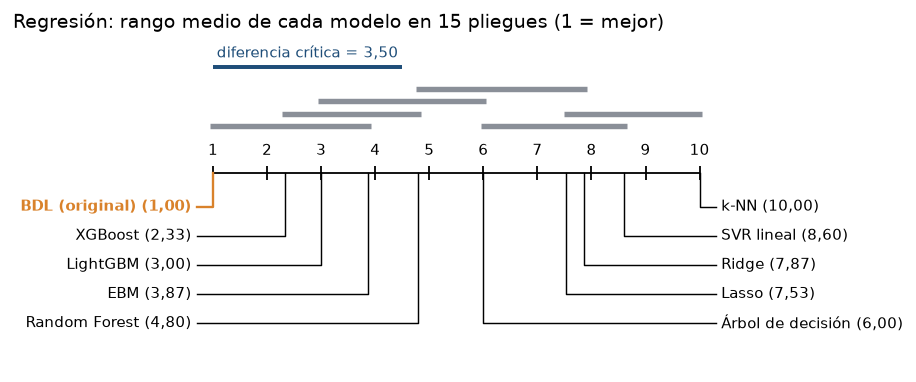

In [8]:
# Figura 6.1. Rangos medios y diferencia crítica de Nemenyi guardados en
# veredicto.json (prueba de Friedman sobre la matriz de pliegues externos × diez
# modelos).
inf.figura('cd_regresion')

(tab-pruebas-clasificacion)=
**Tabla 6.8.** Clasificación: pruebas de hipótesis del modelo original frente al mejor benchmark, con las mismas
columnas, y frente a cada benchmark.

In [9]:
# Tabla 6.8. Lo mismo para la clasificación: P3 es DeLong y P4 es McNemar con la
# campaña del 25 %, las dos en prueba.
inf.tabla('tabla_pruebas_clasificacion')

**Clasificación (AUC, mayor es mejor). Modelo original frente al mejor benchmark, XGBoost.** Ventaja media en los 15 pliegues: −0,00200 (a favor del original en 4). Los p ajustados son de Holm sobre las 9 comparaciones de cada prueba.

| Prueba | Hipótesis nula | Supuestos verificados | Estadístico | p crudo | p ajustado | Tamaño del efecto | Conclusión |
| :--- | :--- | :--- | ---: | ---: | ---: | :--- | :--- |
| Friedman con Iman-Davenport (global) | Los diez modelos rinden igual | 15 bloques completos, 10 modelos | F = 65,7 | < 0,001 | — | — | Rechaza |
| P1. Wilcoxon de rangos con signo | La mediana de las diferencias por pliegue es cero | Pares por pliegue; asimetría de las diferencias 0,68 | 21 | 0,026 | 0,128 | δ = −0,31; *d* = −0,51 | No rechaza |
| P2. *t* corregida de Nadeau-Bengio | La diferencia media por pliegue es cero | Normalidad (Shapiro-Wilk, p = 0,361); varianza corregida por 1/J + 1/4 | −1,1199 | 0,282 | 1,000 | δ = −0,31; *d* = −0,51 | No rechaza |
| P3. DeLong (prueba) | Los dos AUC son iguales | Filas independientes: 2.399 positivos y 7.346 negativos | 1,1385 | 0,255 | 0,765 | — | No rechaza |
| P4. McNemar, campaña del 25 % (prueba) | Los dos aciertan con la misma frecuencia | 1.960 pares discordantes | 20 | 0,668 | 1,000 | — | No rechaza |

Estadísticos: en P1, la menor de las dos sumas de rangos; en P2, *t* de la diferencia original menos benchmark; en P3, *z* de DeLong (positivo: el AUC del original es mayor); en P4, los aciertos que solo tiene el original menos los que solo tiene el benchmark. Tamaño del efecto: δ de Cliff y *d* de Cohen entre los valores por pliegue de los dos modelos, con signo positivo a favor del original; la *d* pareada de las diferencias es −0,63. La diferencia crítica de Nemenyi es 3,50 rangos. Los pliegues de una validación cruzada comparten filas de entrenamiento, de modo que el p de Wilcoxon es optimista; la *t* corregida lo compensa.

**El original frente a cada benchmark** (ventaja positiva: a favor del original; en cada prueba, p crudo / p ajustado por Holm). Son 36 comparaciones en esta tarea (9 benchmarks por 4 pruebas) y 72 en las dos, además de la prueba global de cada una; el ajuste de Holm se hace dentro de cada prueba, sobre sus 9 comparaciones, como fija el protocolo.

| Benchmark | Ventaja media | Pliegues a favor | P1 | P2 | P3 | P4 | δ de Cliff | *d* de Cohen |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| XGBoost | −0,00200 | 4/15 | 0,026 / 0,128 | 0,282 / 1,000 | 0,255 / 0,765 | 0,668 / 1,000 | −0,31 | −0,51 |
| Árbol de decisión | −0,00088 | 7/15 | 0,421 / 1,000 | 0,696 / 1,000 | 0,008 / 0,042 | 0,026 / 0,204 | −0,09 | −0,25 |
| Random Forest | −0,00075 | 6/15 | 0,489 / 1,000 | 0,644 / 1,000 | 0,040 / 0,160 | 0,026 / 0,204 | −0,13 | −0,22 |
| LightGBM | −0,00007 | 7/15 | 0,847 / 1,000 | 0,964 / 1,000 | 0,531 / 0,765 | 0,668 / 1,000 | −0,01 | −0,02 |
| EBM | 0,00193 | 9/15 | 0,169 / 0,675 | 0,466 / 1,000 | 0,375 / 0,765 | 0,804 / 1,000 | 0,28 | 0,47 |
| k-NN | 0,04714 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 0,522 / 1,000 | 1,00 | 8,45 |
| Regresión logística | 0,06685 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 0,705 / 1,000 | 1,00 | 13,37 |
| SVM lineal | 0,06702 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 0,705 / 1,000 | 1,00 | 13,45 |
| Naive Bayes | 0,15976 | 15/15 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | < 0,001 / < 0,001 | 1,00 | 18,32 |


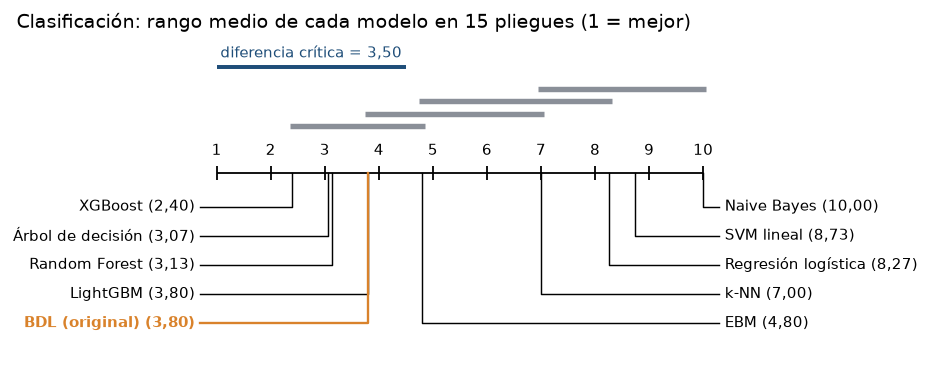

In [10]:
# Figura 6.2. Rangos medios y diferencia crítica de la clasificación
# (veredicto.json).
inf.figura('cd_clasificacion')

**Sobre los supuestos.** Los datos son de corte transversal (un cliente por fila), así que no se usan pruebas que
supongan orden temporal. Los pliegues de una validación cruzada repetida comparten filas de entrenamiento: por eso la
prueba de Wilcoxon se acompaña de la *t* corregida de {cite:t}`nadeau2003`, que infla la varianza para tenerlo en
cuenta, y por eso dos de las cuatro pruebas (P3 y P4) se hacen sobre la partición de prueba, donde las filas sí son
independientes. La prueba
de Nemenyi tiene poca potencia con diez modelos {cite}`demsar2006`: la diferencia crítica es mayor que la distancia
entre los primeros puestos, y los diagramas de las figuras {ref}`6.1 <fig-cd-regresion>` y
{ref}`6.2 <fig-cd-clasificacion>` se presentan como descripción, no como la prueba que decide.

## 6.7. Significancia práctica

In [11]:
# Traduce las diferencias a unidades del problema con veredicto.json,
# metricas_prueba.csv, techo.json e incertidumbre_prueba.csv: error relativo,
# clientes de una campaña del 25 % e intervalos de confianza.
inf.texto('significancia_practica')

**Regresión.** El RMSE medio del original en los pliegues externos es 0,000099 menor que el de XGBoost: el 0,17 % del error del benchmark y el 0,15 % de la desviación típica del puntaje (0,0669). Ninguna decisión sobre un cliente cambia por una diferencia así. Lo que el número deja ver es otra cosa: casi todo el error es irreducible. El predictor óptimo obtiene en prueba 0,05911; por encima de ese valor, XGBoost deja 0,000068 y el original, 0,000010. La diferencia de RMSE en prueba (original menos benchmark) es −0,000058, con un intervalo de confianza del 95 % de [−0,000117; −0,000005] (bootstrap pareado BCa, sin ajustar por comparaciones múltiples), que no incluye el cero. La diferencia que sí se nota está en lo que el modelo sabe del error: como conoce los niveles, puede predecir la mediana en lugar de la media, y el error absoluto medio baja de 0,04706 a 0,04510 (un 4,2 % menos). Parte de esa diferencia es de receta: si al pronóstico de XGBoost se le suma la mediana de sus residuos fuera de pliegue, su error absoluto baja a 0,04566 y la ventaja del original queda en un 1,2 % (comparación exploratoria). Con la misma cobertura nominal del 90 %, su conjunto de predicción mide 0,0062 frente a 0,1905 del intervalo del benchmark. Frente a un conjunto del mismo tipo construido con los residuos de XGBoost (0,0436), unas 7 veces (comparación exploratoria).

**Clasificación.** En una campaña que contacta al 25 % de los clientes de prueba con más riesgo (2.436 de 9.745), el original encuentra el 51,4 % de los 2.399 clientes de riesgo alto y XGBoost, el 51,0 %: 10 clientes más. Esa cifra depende del desempate: 4.354 clientes comparten la probabilidad del corte y solo entran 1.510; con un desempate al azar, la captura esperada del original es 51,3 % ± 0,6 puntos (Tabla 6.11). La diferencia de AUC en prueba es 0,0028, con un intervalo de confianza del 95 % de [−0,0020; 0,0075] (DeLong, sin ajustar por comparaciones múltiples), que incluye el cero; con bootstrap pareado BCa (2.000 réplicas), [−0,0024; 0,0073]. En la práctica las dos campañas encuentran casi el mismo número de clientes de riesgo alto. El original entrega probabilidades que se pueden usar tal como salen: su error de calibración esperado es 0,008. El de XGBoost es 0,216 sin recalibrar, porque se ajustó con ponderación de clases, y 0,007 tras recalibrarlo: la calibración del original no es mejor que la de un benchmark recalibrado; se ahorra ese paso.

**En resumen**, en la métrica principal de las dos tareas la mejora posible era de milésimas y eso es lo que se observa. El aporte práctico del modelo original no es un punto más de precisión: es que describe la estructura del error (cuántos niveles hay, dónde están y con qué probabilidad), que es lo que los benchmarks tratan como ruido.


## 6.8. Veredicto sobre R3

Las condiciones 1 a 3 salen de este capítulo; la 4, de los conjuntos adicionales del capítulo 7. La
{ref}`Tabla 6.9 <tab-veredicto>` las reúne.

(tab-veredicto)=
**Tabla 6.9.** Veredicto sobre la condición R3, por tarea: las cuatro condiciones de la guía (§6.4) y el resultado.

In [12]:
# Tabla 6.9. Lee veredicto.json (condiciones 1 a 3) y condicion4.json (conjuntos
# adicionales). El veredicto se calcula: es «superior» solo si las cuatro
# condiciones se cumplen.
inf.tabla('tabla_veredicto')

| Tarea | Mejor benchmark | 1. Media externa mejor | 2. Al menos tres pruebas rechazan | 3. Efecto no despreciable | 4. Conjuntos adicionales | Veredicto R3 |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| RMSE (regresión) | XGBoost | Sí (0,000099) | No (2 de 4) | Sí (δ = 0,20; *d* = 0,21) | No (mejor en 0 de 4; peor de forma significativa en Vivienda de California) | **No superior** |
| AUC (clasificación) | XGBoost | No (−0,00200) | No (0 de 4) | No (δ = −0,31; *d* = −0,51) | No (mejor en 0 de 4; peor de forma significativa en Seguros médicos, Vivienda de California) | **No superior** |

En las condiciones 1 y 3, el número entre paréntesis es la ventaja del original (positiva: a su favor) y el tamaño del efecto con ese mismo signo. En la 2, las pruebas que rechazan a favor del original con p ajustado < 0,05.


In [13]:
# Discusión del veredicto, con las cifras de los mismos archivos y el análisis de la
# causa cuando no hay superioridad.
inf.texto('veredicto_texto')

**Regresión (H1).** El RMSE medio del modelo original en los 15 pliegues externos es 0,05887, frente a 0,05897 de XGBoost, el mejor benchmark: una ventaja de 0,000099 (0,17 %), con el original por delante en 15 de los 15 pliegues. La condición 1 se cumple. De las 4 pruebas, rechazan la igualdad con XGBoost a favor del original P1 (Wilcoxon; p ajustado < 0,001) y P2 (*t* corregida; p ajustado = 0,001); no rechazan P3 (permutación pareada; p ajustado = 0,092) y P4 (bootstrap pareado; p ajustado = 0,076). La condición 2 pide tres rechazos: no se cumple. El tamaño del efecto entre los valores por pliegue (δ de Cliff = 0,20 y *d* de Cohen = 0,21) supera los umbrales de 0,147 y 0,2: la condición 3 se cumple. En los 4 conjuntos adicionales el original es mejor en 0 de 4; peor de forma significativa en Vivienda de California: la condición 4 no se cumple. **Veredicto: no superior.**

En prueba, el original obtiene 0,05912 (puesto 1 de 10) y XGBoost, 0,05917; el límite teórico es 0,05911, así que el benchmark queda a 0,000068 del límite y el original, a 0,000010. **Causa.** La diferencia es sistemática, pero tan pequeña que, con la corrección por comparaciones múltiples, las pruebas no alcanzan a detectarla todas: el benchmark ya estaba casi en el límite del conjunto y no dejaba margen para una diferencia mayor.

**Clasificación (H2).** El AUC medio del modelo original en los 15 pliegues externos es 0,8313 y el de XGBoost, el mejor benchmark, 0,8333: el original queda en el puesto 5 de 10, a 0,00200 del primero, y va por delante en 4 de los 15 pliegues. La condición 1 no se cumple. Ninguna de las 4 pruebas rechaza la igualdad con XGBoost a favor del original: P1 (Wilcoxon; p ajustado = 0,128), P2 (*t* corregida; p ajustado = 1,000), P3 (DeLong; p ajustado = 0,765) y P4 (McNemar; p ajustado = 1,000). La condición 2 pide tres rechazos: no se cumple. El tamaño del efecto (δ de Cliff = −0,31 y *d* de Cohen = −0,51) va en contra del original: la condición 3 no se cumple. En los 4 conjuntos adicionales el original es mejor en 0 de 4; peor de forma significativa en Seguros médicos, Vivienda de California: la condición 4 no se cumple. **Veredicto: no superior.**

En prueba, el original obtiene 0,8311 (puesto 1 de 10) y XGBoost, 0,8283; el límite teórico es 0,8313, así que el benchmark queda a 0,00301 del límite y el original, a 0,00024. **Análisis de la causa.** El espacio de búsqueda incluía la variante que aprende solo de la etiqueta (`usar_puntaje = False`), y la búsqueda interna la eligió en 7 de los 15 pliegues externos. En esos pliegues el original obtuvo un AUC medio de 0,8295 y XGBoost, 0,8332 (diferencia: −0,0037); en los 8 en que usó el puntaje, 0,8329 frente a 0,8334 (diferencia: −0,0005; por delante en 4 de 8). La desventaja en la media viene sobre todo de los pliegues en que el modelo no usó el puntaje. El modelo final, reajustado con toda la partición de entrenamiento, sí usa el puntaje. En cualquier caso, estas diferencias son menores que la desviación entre pliegues del propio benchmark (0,0041): con estos datos, los primeros modelos de la tabla no se distinguen entre sí en esta tarea. La ablación de la sección 5.9 mide por separado la variante sin puntaje.

**Hipótesis secundarias (no cuentan para R3).** H3: con cobertura nominal del 90 %, el conjunto de predicción del modelo original mide 0,0062 (la unión de 4 tramos) y el intervalo conforme de XGBoost, 0,1905; la cobertura medida en prueba es 89,9 %, dentro del error de muestreo (±0,6 puntos). H3 se cumple. H4: la pérdida logarítmica del original en prueba es 0,3688 y la de XGBoost con sus probabilidades recalibradas, 0,3675 (mínimo teórico: 0,3652). H4 no se cumple; la sección 7.9 muestra de dónde sale la diferencia.

**En conjunto, R3 no se cumple en ninguna de las dos tareas**: con el protocolo registrado, no se puede afirmar que el modelo original supere a los benchmarks.


## 6.9. ¿Podía algún modelo cumplir R3?

La guía pide analizar la causa cuando no hay superioridad. Una forma directa de hacerlo es someter a las mismas pruebas
al **predictor óptimo**, el de la sección 6.4: el que conoce el índice real de cada cliente y aplica la regla de Bayes.
Ningún modelo puede aprenderlo sin la variable excluida. Es el mejor predictor posible en esperanza; en una muestra
finita un modelo puede quedar por delante de él por azar, así que lo que sigue no es una demostración de imposibilidad.
La {ref}`Tabla 6.10 <tab-optimo>` lo somete a las cuatro pruebas del protocolo (P1 y P2 en los pliegues externos, P3 y
P4 en el conjunto de prueba), con el mismo ajuste de Holm sobre nueve comparaciones, y pone al lado las del modelo
original.

Es un análisis posterior a los resultados y no forma parte del protocolo (sección 6.2): no cambia el veredicto, lo
explica.

(tab-optimo)=
**Tabla 6.10.** Las cuatro pruebas del protocolo para el predictor óptimo frente al mejor benchmark, junto a las del
modelo original.

In [14]:
# Tabla 6.10. Lee resultados/optimo.json (experiments/04c_optimo.py). El predictor
# óptimo se construye con el índice real de cada cliente (el puntaje más 0,05 por
# producto activo) y pasa por las mismas pruebas que el original: en los pliegues
# externos de la validación anidada y en el conjunto de prueba.
inf.tabla('tabla_optimo')

| Tarea | Prueba | Mejor benchmark | p crudo del óptimo | p ajustado del óptimo | ¿Rechaza el óptimo? | p ajustado del original | ¿Rechaza el original? |
| :--- | :--- | :--- | ---: | ---: | :--- | ---: | :--- |
| Regresión | P1. Wilcoxon (pliegues externos) | XGBoost | < 0,001 | < 0,001 | Sí | < 0,001 | Sí |
| Regresión | P2. *t* corregida (pliegues externos) | XGBoost | < 0,001 | 0,002 | Sí | 0,001 | Sí |
| Regresión | P3. Permutación pareada (prueba) | XGBoost | 0,023 | 0,046 | Sí | 0,092 | No |
| Regresión | P4. Bootstrap pareado BCa (prueba) | XGBoost | 0,015 | 0,029 | Sí | 0,076 | No |
| Clasificación | P1. Wilcoxon (pliegues externos) | XGBoost | 0,073 | 0,073 | No | 0,128 | No |
| Clasificación | P2. *t* corregida (pliegues externos) | XGBoost | 0,407 | 0,407 | No | 1,000 | No |
| Clasificación | P3. DeLong (prueba) | XGBoost | 0,217 | 0,652 | No | 0,765 | No |
| Clasificación | P4. McNemar, campaña del 25 % (prueba) | XGBoost | 0,737 | 1,000 | No | 1,000 | No |

El predictor óptimo obtiene en prueba un RMSE de 0,05911 y un AUC de 0,8313 (son los valores de referencia de la sección 6.4), y en los 15 pliegues externos, 0,05887 y 0,8348 de media (el original: 0,05887 y 0,8313). Los p ajustados son de Holm sobre las 9 comparaciones de cada prueba, como en el protocolo; un rechazo solo cuenta si la diferencia favorece al modelo. La prueba global de Friedman, que el protocolo exige antes de P1, no se repite para el óptimo.

En clasificación, el predictor óptimo (el que conoce el índice real de cada cliente, que ningún modelo puede aprender sin la variable excluida) no rechaza la igualdad con XGBoost en ninguna de las 4 pruebas. En regresión, el predictor óptimo sí reúne 4 rechazos frente a XGBoost (P1, P2, P3 y P4): con una estimación casi perfecta del índice la condición era alcanzable, y el original se queda en 2.


La lectura es la de la sección 6.4, ahora en términos de las pruebas: los benchmarks están tan cerca del mejor
predictor posible que la distancia que queda es difícil de detectar con este protocolo y estas muestras. La tabla
separa dos causas. Lo que ni el predictor óptimo consigue se debe a los datos: ahí casi no queda nada por ganar en la
métrica principal. Lo que él consigue y el original no se debe al modelo: es el error con que el original estima el
índice.

**Los empates en el corte de la campaña.** En clasificación hay una segunda razón, que afecta a la prueba P4. La
campaña del 25 % contacta a los clientes de mayor probabilidad, y la probabilidad del modelo original, como la del
predictor óptimo, es una función escalonada: miles de clientes comparten el valor del corte. El protocolo no decía cómo
romper esos empates (sección 6.2). La {ref}`Tabla 6.11 <tab-empates>` mide cuánto dependen de esa decisión la captura
de la campaña, la precisión media y el resultado de P4.

(tab-empates)=
**Tabla 6.11.** Empates en el corte de la campaña del 25 %: clientes empatados, captura según el desempate y precisión
media según la convención, para el modelo original, el mejor benchmark, los demás modelos con empates y el predictor
óptimo.

In [15]:
# Tabla 6.11. Lee resultados/empates_campana.json
# (experiments/04d_empates_campana.py): empates de cada modelo en el corte, captura
# esperada con un desempate al azar y la prueba P4 repetida con 2.000 desempates.
inf.tabla('tabla_empates')

**Captura de la campaña del 25 %.**

| Modelo | Valores distintos de la probabilidad | Empatados en el corte | De ellos entran | Captura (protocolo) | Captura esperada (al azar) | Captura posible |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: |
| **BDL (original)** | 219 | 4.354 | 1.510 | 51,4 % | 51,3 % ± 0,6 | 26,0 % a 89,0 % |
| XGBoost | 6.721 | 1 | 1 | 51,0 % | 51,0 % ± 0,0 | 51,0 % a 51,0 % |
| Árbol de decisión | 20 | 1.203 | 332 | 49,5 % | 49,8 % ± 0,3 | 44,3 % a 58,1 % |
| Predictor óptimo | 4 | 4.448 | 1.534 | 51,4 % | 51,3 % ± 0,6 | 25,7 % a 89,6 % |

**Precisión media.**

| Modelo | Convención de scikit-learn | Empates rotos al azar |
| :--- | ---: | ---: |
| **BDL (original)** | 0,5103 | 0,5507 ± 0,0046 |
| XGBoost | 0,5480 | 0,5479 ± 0,0000 |
| Árbol de decisión | 0,5304 | 0,5403 ± 0,0022 |
| Predictor óptimo | 0,5092 | 0,5515 ± 0,0049 |

La campaña contacta a los 2.436 clientes de mayor probabilidad de los 9.745 de prueba. Empatados en el corte: los que tienen la misma probabilidad que el último contactado; de ellos solo entra una parte, y cuál, lo decide el desempate. Protocolo: desempate por posición en la tabla, el del guion de las pruebas. Al azar: valor esperado ± desviación típica, en puntos porcentuales (distribución hipergeométrica); en la precisión media, media ± desviación de 200 desempates.

**Lectura.** La probabilidad del original toma 219 valores distintos y la del predictor óptimo, 4: es una función escalonada, y dentro de una meseta todos los clientes tienen la misma probabilidad (Proposición 5). El corte de la campaña cae dentro de una meseta: 4.354 clientes comparten la probabilidad del último contactado y solo entran 1.510. La captura del original con el desempate del protocolo, 51,4 %, es uno de los valores posibles: con un desempate al azar se espera 51,3 % ± 0,6 puntos, lo mismo que con el predictor óptimo (51,3 %). La diferencia con XGBoost (51,0 %) es menor que esa variación.

**Qué significa para P4.** Repetida con 2.000 desempates al azar de los dos modelos, la prueba de McNemar del original frente a XGBoost da un p crudo con mediana 0,638 (entre 0,099 y 0,982 en el 95 % de los desempates). Tras el ajuste de Holm sobre las 9 comparaciones, rechaza la igualdad a favor del original en el 0,15 % de los desempates y en contra en el 0,00 %. El resultado registrado (no rechaza; p ajustado = 1,000) no depende del desempate: es el de casi todos los sorteos. Pero deja ver qué mide la prueba en este conjunto: dentro de la meseta del corte, el original y el predictor óptimo eligen al azar.

**Precisión media.** scikit-learn trata a los clientes empatados como un solo punto de la curva de precisión y exhaustividad, con la precisión del grupo entero. Con mesetas grandes eso da menos que cualquier orden concreto dentro de ellas: 0,5103 para el original y 0,5092 para el predictor óptimo, por debajo de XGBoost (0,5480). Con los empates rotos al azar son 0,5507 y 0,5515: la desventaja del original en esa columna de la Tabla 7.11 viene de la convención, no del orden que da el modelo.

El dashboard rompe los empates al azar con su propia semilla, como el Entregable 3, y muestra una captura de 51,9 % para el original: es otro sorteo de la misma distribución, a 0,9 desviaciones del valor esperado.
